# Задача 1

а) Суммируем стоимость префикса и истории по шагам. Получаем α(S + D)T + hT(T + 1)/2. Заменяем T + 1 на T, то есть отбрасываем hT/2. Итог: C ≈ α(S + D)T + hT²/2.

б)

In [1]:
S = 2000
D = 55000
h = 1500
T = 40

history = h * T**2 / 2

for alpha in [1, 0.1]:
    prefix = alpha * (S + D) * T
    total = prefix + history
    print(f"alpha = {alpha}")
    print(f"Префикс: {prefix:.0f}")
    print(f"История: {history:.0f}")
    print(f"Стоимость: {total:.0f}")
    print(f"Доля истории: {history / total:.2%}")
    print()


alpha = 1
Префикс: 2280000
История: 1200000
Стоимость: 3480000
Доля истории: 34.48%

alpha = 0.1
Префикс: 228000
История: 1200000
Стоимость: 1428000
Доля истории: 84.03%



In [2]:
for alpha in [1, 0.1]:
    saving_D = alpha * (D * 0.1) * T
    saving_alpha = (alpha * 0.1) * (S + D) * T
    saving_h = (h * 0.1) * T**2 / 2
    print(f"При alpha = {alpha}, уменьшение на 10%:")
    print(f"D: экономия {saving_D:.0f}")
    print(f"alpha: экономия {saving_alpha:.0f}")
    print(f"h: экономия {saving_h:.0f}")
    print()


При alpha = 1, уменьшение на 10%:
D: экономия 220000
alpha: экономия 228000
h: экономия 120000

При alpha = 0.1, уменьшение на 10%:
D: экономия 22000
alpha: экономия 22800
h: экономия 120000



Без кэша выгоднее уменьшать α, чуть меньше экономия от D. После кэширования история занимает 84,03% стоимости, поэтому выгоднее уменьшать h. Здесь сравниваем одинаковое относительное уменьшение параметров на 10%.

в)

In [3]:
d = 300
s = 500
k = 5

cost_B = s + k * d
N = cost_B // d + 1

print(f"B: {cost_B} токенов")
print(f"Минимальное N: {N}")
print(f"A при N = {N}: {N * d} токенов")
print(f"A при N = {N - 1}: {(N - 1) * d} токенов")


B: 2000 токенов
Минимальное N: 7
A при N = 7: 2100 токенов
A при N = 6: 1800 токенов


г)

In [4]:
recall = 0.95
accuracy_5 = 0.90
accuracy_B = recall * accuracy_5

print(f"Точность B: {accuracy_B:.1%}")
print(f"B перестаёт выигрывать при A(N) >= {accuracy_B:.3f}")


Точность B: 85.5%
B перестаёт выигрывать при A(N) >= 0.855


При A(N) = 85,5% точность равна, выше — A точнее.

Почему оценка B слишком оптимистична:

1. Не учтены расходы на эмбеддинги, поиск и возможный дополнительный вызов модели.
2. Поиск может собрать очень похожие инструменты. Выбирать среди них сложнее, поэтому A(5) нужно измерять на найденных пятёрках при наличии правильного инструмента.

# Задача 3

Часть A. Пул и запросы сохранены после пилота, поиск не меняли. Ошибки считаются неправильными ответами. Основной прогон: 720 попыток.

In [5]:
import json
from pathlib import Path

from experiment import MODEL, TEMPERATURE, MAX_TOKENS, load_data, prepare_retrieval, run_selection
from experiment import selection_summary, loop_summary, accuracy_plot

print("Модель:", MODEL)
print("Температура:", TEMPERATURE)
print("Максимум выходных токенов:", MAX_TOKENS)


Модель: unsloth/qwen3.5-4b
Температура: 0.3
Максимум выходных токенов: 256


In [6]:
data = load_data()
retrieval = prepare_retrieval(data)

print("Инструментов:", len(data["pool"]))
print("Запросов:", len(data["queries"]))

for N in [5, 20, 50, 100]:
    hits = 0
    for query in data["queries"]:
        if query["correct_tool"] in retrieval[str(N)][query["id"]]["names"]:
            hits += 1
    print(f"N={N}: Recall@5 = {hits}/30 = {hits / 30:.1%}")


Инструментов: 100
Запросов: 30
N=5: Recall@5 = 30/30 = 100.0%
N=20: Recall@5 = 22/30 = 73.3%
N=50: Recall@5 = 19/30 = 63.3%
N=100: Recall@5 = 14/30 = 46.7%


Основная логика в experiment.py. При повторном запуске уже записанные попытки не повторяются; ошибки тоже остаются в data.json.

In [7]:
run_selection()


Часть A завершена: 720 попыток


In [8]:
selection = selection_summary()


  N variant  attempts  correct  accuracy   ci_low  ci_high  recall_at_5  input_tokens  token_records  errors
  5       A        90       90  1.000000 1.000000 1.000000     1.000000    173.166667             90       0
  5       B        90       90  1.000000 1.000000 1.000000     1.000000    173.166667             90       0
 20       A        90       85  0.944444 0.855556 1.000000     0.733333    509.166667             90       0
 20       B        90       63  0.700000 0.533333 0.866667     0.733333    178.500000             90       0
 50       A        90       90  1.000000 1.000000 1.000000     0.633333   1125.166667             90       0
 50       B        90       57  0.633333 0.466667 0.800000     0.633333    178.600000             90       0
100       A        90       89  0.988889 0.966667 1.000000     0.466667   2267.166667             90       0
100       B        90       42  0.466667 0.300000 0.633333     0.466667    185.700000             90       0


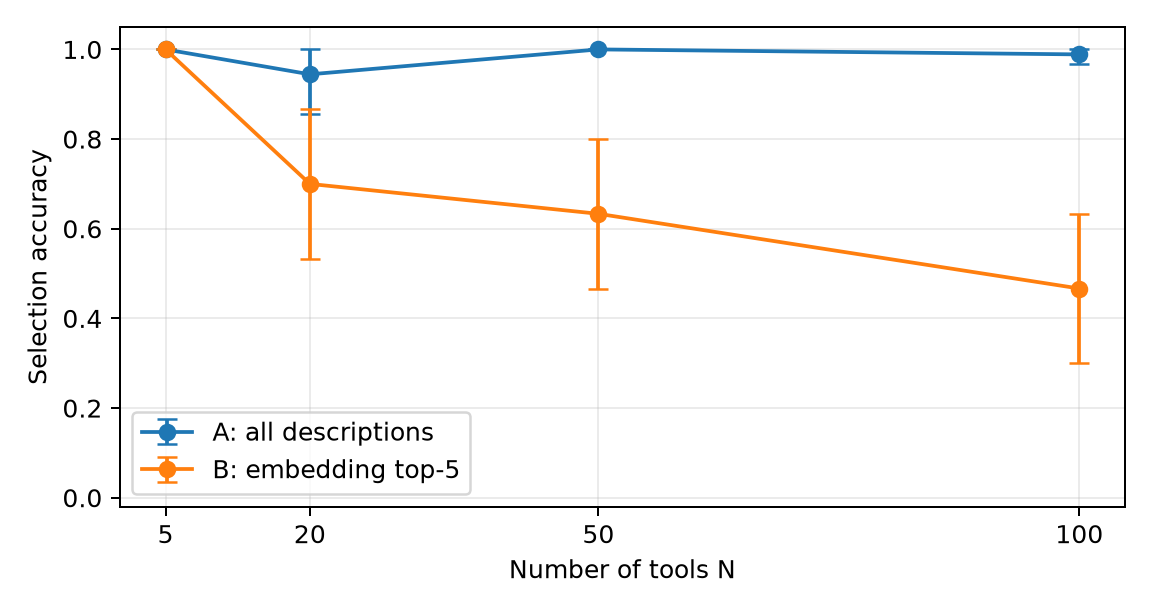

In [9]:
from IPython.display import Image, display

display(Image(data=accuracy_plot(selection)))


Часть B. 20 задач в каждом из трёх условий, до 10 шагов на эпизод. Вероятность пустого ответа поиска 0,5. Код LoopGuard из лекции сохранён в experiment.py. Guard передаёт подсказку модели, а метрика петли отдельно проверяет три одинаковых вызова подряд или A-B-A-B.

In [10]:
from experiment import run_loops

await run_loops()


In [11]:
loops = loop_summary()


condition  episodes  loops  loop_rate  successes  success_rate  mean_steps  mean_input_tokens  mean_output_tokens  mean_total_tokens  usage_complete  errors  step_limits  guard_signals
    empty        20      0        0.0         15          0.75        3.85            1636.75               86.70            1723.45              20       1            1              0
    guard        20      0        0.0         16          0.80        3.55            1424.15               77.95            1502.10              20       2            0              0
     hint        20      0        0.0         16          0.80        4.35            2074.45              101.30            2175.75              20       0            2              0


In [12]:
for _, row in loops.iterrows():
    print(
        row["condition"],
        "петли:", f"{int(row['loops'])}/20",
        "успех:", f"{int(row['successes'])}/20",
        "средние шаги:", round(row["mean_steps"], 2),
    )


empty петли: 0/20 успех: 15/20 средние шаги: 3.85
guard петли: 0/20 успех: 16/20 средние шаги: 3.55
hint петли: 0/20 успех: 16/20 средние шаги: 4.35


Угрозы валидности:

1. Данные синтетические, один небольшой домен и похожие запросы.
2. Одна квантованная модель и один способ эмбеддингов; названия, ID и отрицания могут ухудшать поиск.
3. Только 20 задач с искусственными сбоями и бюджетом 10 шагов. Результаты не доказывают универсальное преимущество метода.

In [13]:
import subprocess
import sys

result = subprocess.run(
    [sys.executable, "-m", "pytest", "test_project.py", "-q", "-p", "no:cacheprovider"],
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Тесты не прошли")


.......................                                                  [100%]
23 passed in 0.57s

